<a href="https://colab.research.google.com/github/matbarrett/LinAlgProject/blob/main/notebooks/01%20image%20as%20matrix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Checkpoint 1

An image is an array of pixel values. Here we look at those values and use a few small patterns to see what matrix rank means.

In [1]:
from pathlib import Path
import subprocess
import sys

# Use this checkout locally, or download the project when running in Colab.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "bird_image.jpg").exists() and (p / "src").is_dir()), None)
if ROOT is None:
    ROOT = Path.cwd() / "LinAlgProject"
    if (ROOT / ".git").exists():
        subprocess.run(["git", "-C", str(ROOT), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "https://github.com/matbarrett/LinAlgProject.git",
                        str(ROOT)], check=True)
sys.path.insert(0, str(ROOT / "src"))
print("Project:", ROOT.name)

Project: LinAlgProject


This loads the files from the project folder, or downloads them when using Colab. The bird photo is saved in the repo, so there is no upload step.

In [2]:
# import libraries
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
# load image of cameraman
A = data.camera()

NumPy handles the arrays, Matplotlib displays them, and scikit-image provides the sample photos. `A` is the camera image before any calculations.

In [3]:
print("Shape:", A.shape) # print dimensions
print("Data type:", A.dtype) # print value type
print("Smallest entry:", A.min()) # print lowest pixel brightness
print("Largest entry:", A.max()) # highest pixel brightness
print("Top-left 3 x 3 block:\n", A[:3, :3]) # array of brightness

Shape: (512, 512)
Data type: uint8
Smallest entry: 0
Largest entry: 255
Top-left 3 x 3 block:
 [[200 200 200]
 [200 199 199]
 [199 199 199]]


The camera image is 512 by 512. Its `uint8` entries are whole numbers between 0 and 255. Printing a small corner shows the brightness values for those pixels.

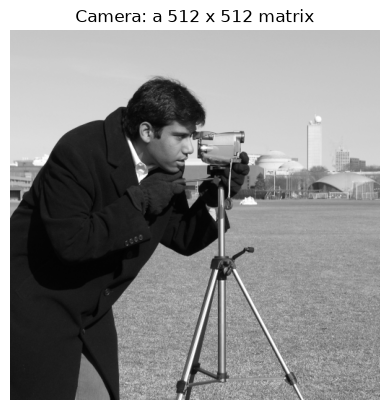

In [4]:
plt.imshow(A, cmap="gray", vmin=0, vmax=255) # turn array into image (A is brightness, cmap is shade, colors)
plt.title("Camera: a 512 x 512 matrix") # image title
plt.axis("off") # no ticks or axes
plt.show() # show image

The gray color map makes low values dark and high values light. Fixing the display range at 0 to 255 keeps the brightness scale consistent.

Color image shape: (512, 512, 3)


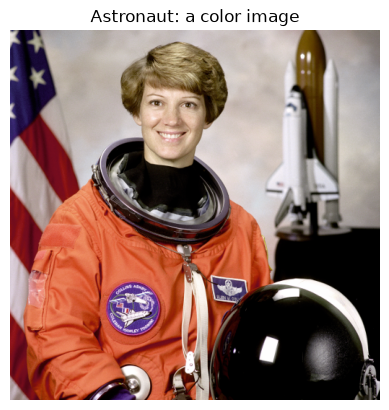

In [5]:
# load astronaut image
C = data.astronaut()
print("Color image shape:", C.shape) # dimensions
plt.imshow(C) # used to display color image
plt.title("Astronaut: a color image")
plt.axis("off")
plt.show()

A color image needs three values per pixel. The last dimension of the astronaut array is for red, green, and blue.

In [6]:
# Color channels
R = C[:, :, 0] # red channel
G = C[:, :, 1] # green channel
B = C[:, :, 2] # blue channel
print("Red channel shape:", R.shape)
print("Green channel shape:", G.shape)
print("Blue channel shape:", B.shape)

Red channel shape: (512, 512)
Green channel shape: (512, 512)
Blue channel shape: (512, 512)


Each slice keeps all rows and columns but selects one color channel. That leaves three separate 512 by 512 matrices.

In [7]:
x = np.array([200], dtype=np.uint8)
y = np.array([100], dtype=np.uint8)
print("uint8 200 + 100 =", x + y)
print("float 200 + 100 =", x.astype(float) + y.astype(float))

uint8 200 + 100 = [44]
float 200 + 100 = [300.]


The integer result is 44 because 300 wraps around modulo 256. Converting to float first gives 300, so we need floats before doing image arithmetic.

In [8]:
# small images in arrays
cross = np.array([
  [0, 1, 1, 0],
  [1, 1, 1, 1],
  [1, 1, 1, 1],
  [0, 1, 1, 0]
])
gradient = np.array([
[i + j for j in range(4)]
for i in range(4)
])
checker = np.array([
[(i + j + 1) % 2 for j in range(4)]
for i in range(4)
])

The checkerboard repeats two rows. In the gradient, moving one space to the right or down adds 1 to the pixel value.

In [9]:
print("Cross rank =", np.linalg.matrix_rank(cross))
print("Gradient rank =", np.linalg.matrix_rank(gradient))
print("Checkerboard rank =", np.linalg.matrix_rank(checker))

Cross rank = 2
Gradient rank = 2
Checkerboard rank = 2


All three ranks are 2. The checkerboard has lots of alternating squares, but only two independent row patterns.

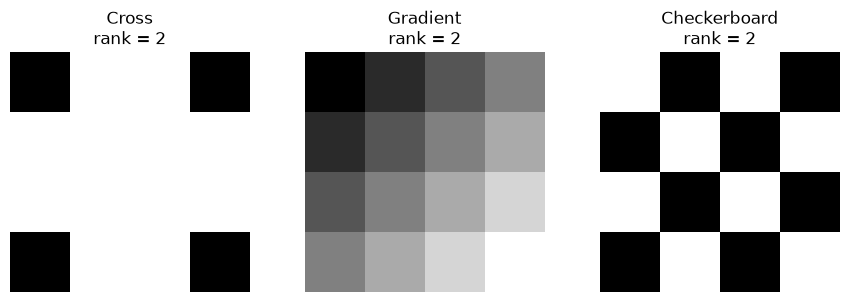

In [10]:
# checkerboard image
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
images = [("Cross", cross), ("Gradient", gradient),
("Checkerboard", checker)]
for ax, (name, M) in zip(axes, images):
  ax.imshow(M, cmap="gray", vmin=0, vmax=M.max())
  ax.set_title(f"{name}\nrank = {np.linalg.matrix_rank(M)}")
  ax.axis("off")
plt.tight_layout()
plt.show()

The gradient goes from 0 to 6, so its display range needs to match. With a maximum of 1, most of it would just look white.

[[1 1 1 1]
 [0 0 0 0]
 [1 1 1 1]
 [0 0 0 0]]
Rank = 1


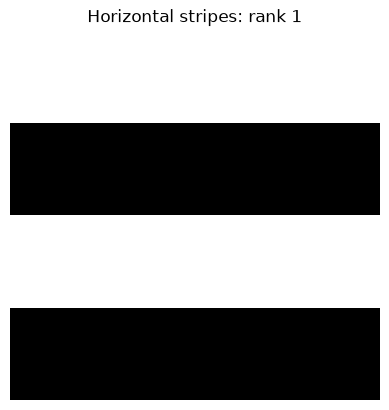

In [11]:
# stripe image
u = np.array([1, 0, 1, 0])
v = np.array([1, 1, 1, 1])
stripes = np.outer(u, v)
print(stripes)
print("Rank =", np.linalg.matrix_rank(stripes))
plt.imshow(stripes, cmap="gray", vmin=0, vmax=1)
plt.title("Horizontal stripes: rank 1")
plt.axis("off")
plt.show()

The stripe matrix is an outer product. Each row is either the same row of ones or a zero row, so only one independent row is needed.

## Project photograph

Shape: (678, 452)
Data type: uint8


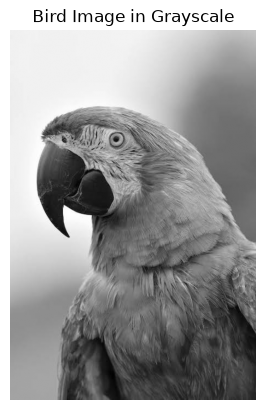

In [12]:
from PIL import Image

img = Image.open(ROOT / "bird_image.jpg").convert("L")
img.thumbnail((800, 800))
P = np.array(img)
print("Shape:", P.shape)
print("Data type:", P.dtype)
plt.imshow(P, cmap="gray", vmin=0, vmax=255)
plt.title("Bird Image in Grayscale")
plt.axis("off")
plt.show()

`convert("L")` turns the bird photo into grayscale. `thumbnail` keeps the proportions while limiting the size to 800 pixels in either direction. The resulting array is `P`.

## Practice exercises

### 1. Pixel values
A value of 18 is very dark, close to black. A value of 127 is a middle gray. A value of 245 is very light, close to white.

### 2. Image shape
A `(600, 900, 3)` image has 600 rows, 900 columns, and 3 color channels. It stores `600 * 900 * 3 = 1,620,000` numbers.

### 3. Slicing a matrix

In [13]:
print(A[:5, :5])

[[200 200 200 200 199]
 [200 199 199 200 199]
 [199 199 199 200 200]
 [200 200 199 199 199]
 [200 200 200 200 199]]


The first `:5` selects rows 0 through 4. The second selects columns 0 through 4. The stopping index is excluded, so this gives the top-left 5 by 5 block.

### 4. Avoiding overflow

In [14]:
a = np.array([250], dtype=np.uint8)
b = np.array([20], dtype=np.uint8)
print("uint8:", a + b)
print("float:", a.astype(float) + b.astype(float))

uint8: [14]
float: [270.]


The true sum is 270. With `uint8`, it wraps to 14 because `270 - 256 = 14`. Converting both inputs before addition avoids the wraparound. Converting after addition would be too late.

### 5. A new tiny image
We use a diagonal of four white pixels. The predicted rank is 4 because each row has its nonzero entry in a different column.

[[1 0 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]]
Predicted rank: 4
Computed rank: 4


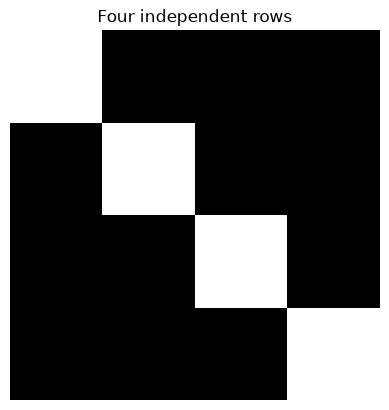

In [15]:
tiny = np.eye(4, dtype=int)
print(tiny)
print("Predicted rank: 4")
print("Computed rank:", np.linalg.matrix_rank(tiny))
plt.imshow(tiny, cmap="gray", vmin=0, vmax=1)
plt.title("Four independent rows")
plt.axis("off")
plt.show()

The rank is 4, as predicted. Each row has a 1 in a different column, so none can be made by combining the other rows.

### 6. Rank-1 design

[[0 1 0 1]
 [0 1 0 1]
 [0 0 0 0]
 [0 0 0 0]]
Rank: 1


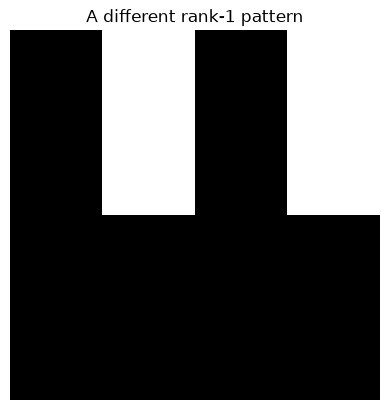

In [16]:
u_new = np.array([1, 1, 0, 0])
v_new = np.array([0, 1, 0, 1])
design = np.outer(u_new, v_new)
print(design)
print("Rank:", np.linalg.matrix_rank(design))
plt.imshow(design, cmap="gray", vmin=0, vmax=1)
plt.title("A different rank-1 pattern")
plt.axis("off")
plt.show()

Every row is a multiple of `[0, 1, 0, 1]`: the first two use multiplier 1 and the last two use 0. Both vectors are nonzero, so the matrix has rank 1, not 0.